# 🎯 第 2 课：监督学习与无监督学习
### 吴恩达《Machine Learning Specialization》· Course 1 · Week 1 · Lesson 2

---

**承上**：第 1 课我们知道了"机器学习 = 从例子里自己学规律"。
**这一课**：世上机器学习任务千千万，先归成**两大类**——**监督学习**和**无监督学习**，把它们的区别彻底搞懂。

**怎么用**：从头往下读，灰色代码格按 `Shift + Enter` 运行，看图找感觉。

## 第 0 步：环境自检

运行下面这格，确认画图工具就绪、中文字体也设好。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
# ---- 选择你电脑上存在的中文字体：Windows 用微软雅黑，Mac 用苹方，Linux 用 Noto ----
_candidates = ["Microsoft YaHei", "SimHei", "PingFang SC",
               "Noto Sans CJK JP", "Noto Sans CJK SC", "Droid Sans Fallback"]
_available = {f.name for f in font_manager.fontManager.ttflist}
_chosen = [c for c in _candidates if c in _available] or ["DejaVu Sans"]
plt.rcParams["font.sans-serif"] = _chosen
plt.rcParams["axes.unicode_minus"] = False
print("本次使用中文字体：", _chosen)
print("✅ 环境就绪，可以继续啦！")

本次使用中文字体： ['Microsoft YaHei', 'SimHei']
✅ 环境就绪，可以继续啦！


---

## 一、两大家族总览

1. **监督学习（Supervised Learning）**
2. **无监督学习（Unsupervised Learning）**

**一句话区分：**

- 监督学习 = **有老师、有标准答案**（数据带"标签 label"）
- 无监督学习 = **没老师、没标准答案**（数据没标签，自己去发现结构）

**生活类比：**
- 监督学习像**做一本带答案的练习册**：做完能对答案，从而知道自己错在哪、怎么改。
- 无监督学习像**面对一屋子没整理的东西**：没人告诉你该怎么分类，你自己观察、自己归类。

### 2.1 监督学习（有标签、有"标准答案"）

关键：**每一条数据都有"正确答案"。** 监督学习里最常见的两个任务：

**① 回归（Regression）——预测一个"连续的数值"**
- 例：根据房子面积预测房价
- 输出是**一根数轴上的某个数**

**② 分类（Classification）——预测一个"类别"**
- 例：根据肿瘤大小判断是良性还是恶性
- 输出是**有限几个类别**（是/否、良性/恶性、猫/狗/鸟）

> 🔑 一句话记住：**回归猜数值，分类猜类别。**

下面用两张图，让你"亲眼看"到它们的区别。

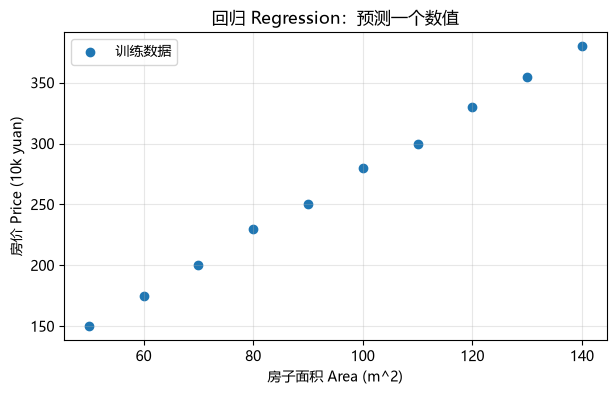

In [2]:
# ===== 图 1：回归 —— 用面积预测房价 =====
area  = np.array([50, 60, 70, 80, 90, 100, 110, 120, 130, 140])  # 面积(平方米)
price = np.array([150, 175, 200, 230, 250, 280, 300, 330, 355, 380])  # 房价(万元)
# ↑ 这些房价就是"标准答案"，所以这是【监督学习】

plt.figure(figsize=(7, 4))
plt.scatter(area, price, color='tab:blue', label='训练数据')
plt.xlabel('房子面积 Area (m^2)')      # x 轴标签
plt.ylabel('房价 Price (10k yuan)')   # y 轴标签
plt.title('回归 Regression：预测一个数值')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

**👀 观察：** 这些点几乎排成一条**上升的直线**。所以我们能画一条线去"贴合"它们，以后来一套新房，顺着线就能**估出一个具体价格**。这就是**回归**——猜出来的是一个**连续的数字**。

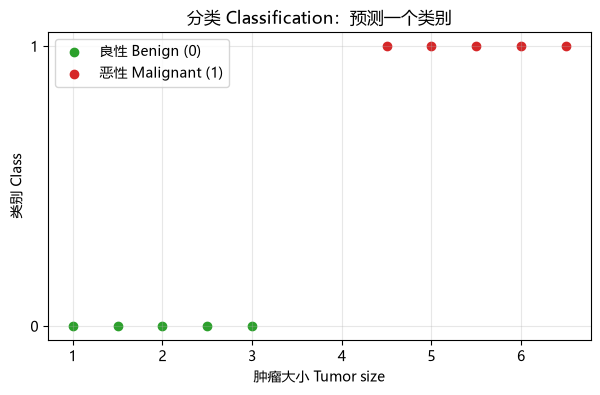

In [3]:
# ===== 图 2：分类 —— 判断肿瘤是良性还是恶性 =====
# 0 = 良性, 1 = 恶性。y 轴只有两个可能的值。
benign_size = np.array([1.0, 1.5, 2.0, 2.5, 3.0])     # 小肿瘤（偏良性）
benign_color = np.zeros(len(benign_size))             # 对应标签全是 0
malig_size  = np.array([4.5, 5.0, 5.5, 6.0, 6.5])     # 大肿瘤（偏恶性）
malig_color = np.ones(len(malig_size))                # 对应标签全是 1

plt.figure(figsize=(7, 4))
plt.scatter(benign_size, benign_color, color='tab:green', label='良性 Benign (0)')
plt.scatter(malig_size,  malig_color,  color='tab:red',   label='恶性 Malignant (1)')
plt.yticks([0, 1])
plt.xlabel('肿瘤大小 Tumor size')
plt.ylabel('类别 Class')
plt.title('分类 Classification：预测一个类别')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

**👀 观察：** 这里我们不是要猜"精确数值"，而是要**画一条线把两种颜色分开**，好判断新来的肿瘤落在哪一边。这就是**分类**——猜出来的是一个**类别**。

（补充：分类不一定只有两类，比如"猫 / 狗 / 鸟"就是 3 类。）

### 2.2 监督学习的正式记号（数学登场了）

监督学习的数据长这样：一叠 **"输入 + 答案"** 的配对。给它们起几个正式名字：

| 记号 | 名字 | 大白话 |
|---|---|---|
| `x` | 输入特征（feature） | 你手里已知的信息，比如**房子面积** |
| `y` | 目标 / 标签（target） | 你要预测的答案，比如**房价** |
| `m` | 样本数量 | 你一共有**几套**房子的数据 |
| `(x, y)` | 一个训练样本 | 一套房：它的面积 + 它的房价 |
| `(x⁽ⁱ⁾, y⁽ⁱ⁾)` | 第 i 个训练样本 | 第 i 套房（**上标带括号 = "第几个"，不是次方！**） |

这一整叠配对，就叫**训练集（training set）**。下面用真实房价数据把它画出来：

一共有 m = 9 个训练样本
x（面积）: [ 50  75 100 125 150 175 200 225 250]
y（房价）: [150 180 220 260 295 340 375 420 455]


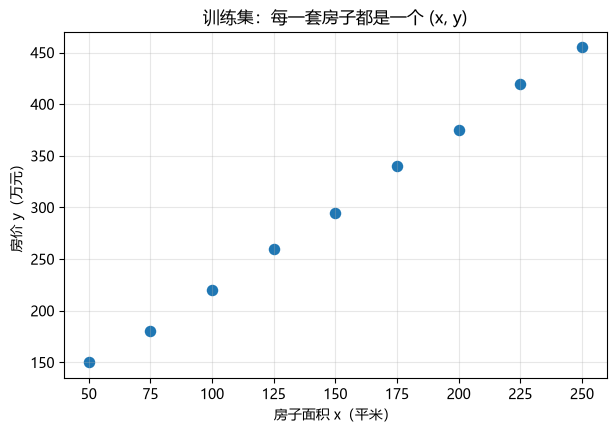

In [4]:
# ===== 我们的训练集：9 套房子的面积和房价 =====
x = np.array([50, 75, 100, 125, 150, 175, 200, 225, 250])   # 输入特征 x = 面积(平米)
y = np.array([150, 180, 220, 260, 295, 340, 375, 420, 455]) # 目标 y = 房价(万元)
m = len(x)                                                  # 样本数量 m

print("一共有 m =", m, "个训练样本")
print("x（面积）:", x)
print("y（房价）:", y)

plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, s=90, color="tab:blue", edgecolor="white", linewidth=1.2)
plt.xlabel("房子面积 x（平米）")
plt.ylabel("房价 y（万元）")
plt.title("训练集：每一套房子都是一个 (x, y)")
plt.grid(alpha=0.3)
plt.show()

**👀 看**：每个蓝点就是一套房子——横坐标是面积 x，纵坐标是房价 y。这就是**监督学习**的样子：我们知道每个点"正确答案"的高度。

（这份数据下一课还会用到，用来请出第一个真正的公式。）

---

### 三、无监督学习（没标签、没"标准答案"）

关键：**数据没有标签，让算法自己找出结构。**

最典型的一类是**聚类（Clustering）**——把相似的东西**自动归到一堆**。

**真实例子：**
- **Google 新闻**：把成千上万篇新闻自动分到"体育 / 财经 / 科技"等板块（它事先并不知道有哪些类别！）
- **电商**：把顾客按购买习惯自动分成几群人（"市场细分"），用来做精准推荐
- **鸡尾酒会问题**：把两个人重叠的声音，拆成各自单独的录音

看下图你就懂了：

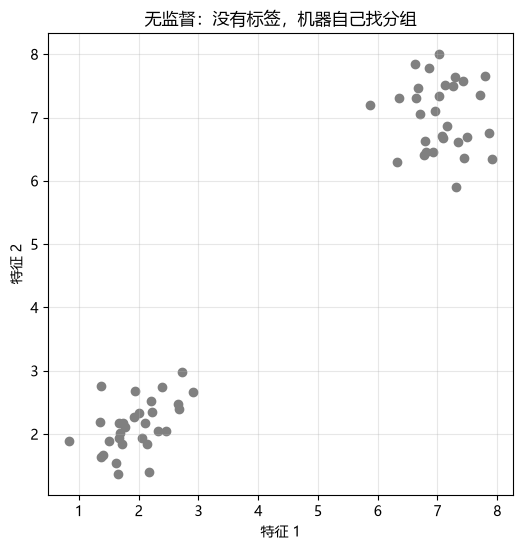

In [5]:
# ===== 图 3：聚类 —— 没有标签，机器自己分堆 =====
rng = np.random.default_rng(0)                              # 固定随机种子，保证结果一样
cluster1 = rng.normal(loc=(2, 2), scale=0.5, size=(30, 2))  # 左下角的一团点
cluster2 = rng.normal(loc=(7, 7), scale=0.5, size=(30, 2))  # 右上角的一团点
all_points = np.vstack([cluster1, cluster2])                # 把两团混在一起

plt.figure(figsize=(6, 6))
plt.scatter(all_points[:, 0], all_points[:, 1], color='gray')  # 全是灰色，没有颜色标签
plt.xlabel('特征 1'); plt.ylabel('特征 2')
plt.title('无监督：没有标签，机器自己找分组')
plt.grid(alpha=0.3)
plt.show()

**👀 观察：** 点**自己明显分成两团**——而我们**没有给任何标签**。人一眼看出"应该分两堆"，机器也能自己找到。这就是**无监督学习**：**没有标准答案，自己发现结构。**

---

## 四、一张表，把这一课记住

| 类型 | 有标签吗？ | 例子 | 要干嘛 |
|---|---|---|---|
| 监督学习 · **回归** | ✅ 有 | 房价预测 | 猜**数值** |
| 监督学习 · **分类** | ✅ 有 | 肿瘤良/恶 | 猜**类别** |
| 无监督学习 · **聚类** | ❌ 无 | 新闻自动分组 | 自己**分堆** |

---

## 五、反转课堂 · 课后作业 📝

看完视频后，把答案发我，我们逐个过：

1. 用一句话向完全不懂的朋友解释：**监督学习和无监督学习**的区别。
2. 下面哪一个是**监督学习**？(a) 把邮件分成"垃圾 / 正常"　(b) 把顾客按购买习惯自动分成几群
3. "预测病人**住院天数**"是回归还是分类？为什么？

---

👉 **下一课（第 3 课）：线性回归模型**——我们会把监督学习变成一个真正的公式 `f(x)=wx+b`。